In [1]:
# !pip install geopandas shapely contextily

In [2]:
# !pip install polars

In [3]:
# !pip install polyline requests

In [ ]:
# import sys
# import os

# # Xác định thư mục gốc của dự án (lùi ra 1 cấp so với thư mục notebooks)
# project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# # Thêm thư mục gốc vào sys.path để Python có thể tìm thấy bus_benchmark
# if project_root not in sys.path:
#     sys.path.append(project_root)

# Vẽ lộ trình đi từ file parquet dataset

Route: 148457 | Trip: RET:897592:0 | Ngày: 2022-08-23 00:00:00
Đang gọi OSRM API để lấy dữ liệu đường phố (Có thể mất vài giây)...


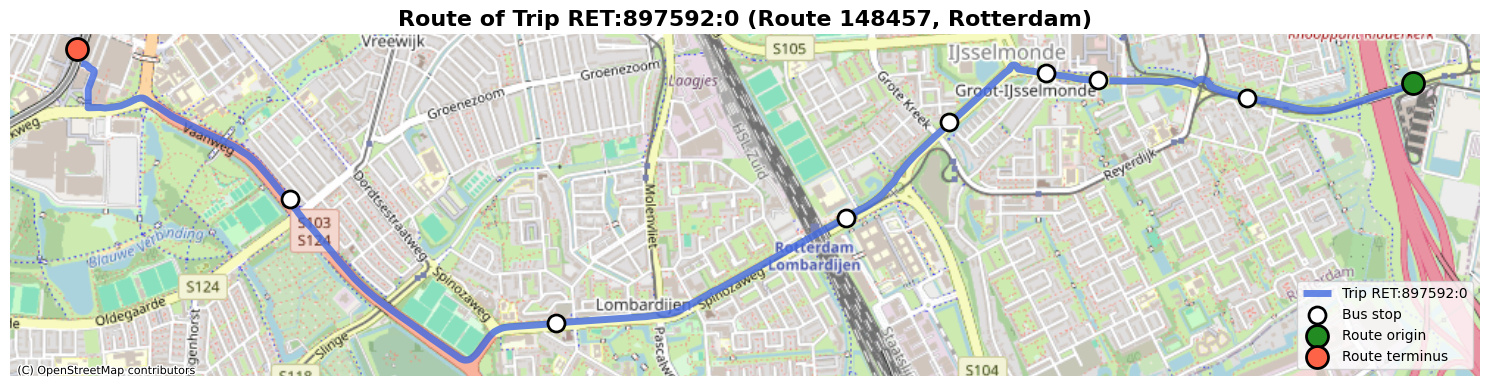

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely import wkt
from shapely.geometry import LineString
import matplotlib.pyplot as plt
import contextily as ctx
import requests
import polyline
import time

# ========================================================
# HÀM HỖ TRỢ: LẤY ĐƯỜNG ĐI THỰC TẾ TỪ OSRM API
# ========================================================
def get_route_osrm(point1, point2):
    """
    Gọi OSRM API để lấy đường đi thực tế giữa 2 điểm (lon, lat).
    """
    # OSRM yêu cầu định dạng: {lon},{lat}
    url = f"http://router.project-osrm.org/route/v1/driving/{point1.x},{point1.y};{point2.x},{point2.y}?overview=full&geometries=polyline"
    
    try:
        response = requests.get(url)
        if response.status_code == 200:
            data = response.json()
            if data['code'] == 'Ok':
                # Giải mã polyline (trả về list các tuple (lat, lon))
                route_coords = polyline.decode(data['routes'][0]['geometry'])
                # Đổi ngược lại thành (lon, lat) cho Shapely
                route_coords = [(lon, lat) for lat, lon in route_coords]
                return LineString(route_coords)
    except Exception as e:
        print(f"Lỗi gọi API: {e}")
        
    # Nếu API lỗi hoặc không tìm thấy đường, fallback về đường thẳng nối 2 điểm
    return LineString([point1, point2])

# ========================================================
# 1. TẢI VÀ LỌC DỮ LIỆU
# ========================================================
data_set = "Rotterdam"
lau_id = "GM0599"

df_parquet = pd.read_parquet(f"../data/parquet_data/{lau_id}.parquet")
df_parquet['from_time'] = df_parquet['from_time'].dt.tz_convert('Europe/Amsterdam')

top_route = df_parquet['route'].mode()[0]
df_route = df_parquet[df_parquet["route"] == top_route]

sample_trip = df_route['trip'].mode()[0]
df_trip = df_route[df_route['trip'] == sample_trip].copy()

sample_date = df_trip['date'].iloc[0]  
df_trip_single_day = df_trip[df_trip['date'] == sample_date].copy().sort_values('from_time')

print(f"Route: {top_route} | Trip: {sample_trip} | Ngày: {sample_date}")

# ========================================================
# 2. XỬ LÝ GEOMETRY & GỌI API ĐỂ TẠO LỘ TRÌNH BO ĐƯỜNG
# ========================================================
df_trip_single_day['from_point'] = df_trip_single_day['from_geometry'].apply(wkt.loads)
df_trip_single_day['to_point'] = df_trip_single_day['to_geometry'].apply(wkt.loads)

print("Đang gọi OSRM API để lấy dữ liệu đường phố (Có thể mất vài giây)...")
# Áp dụng hàm get_route_osrm cho từng đoạn. 
# Thêm time.sleep(0.1) nếu API báo lỗi "Too Many Requests" do gọi quá nhanh
df_trip_single_day['line_geom'] = df_trip_single_day.apply(
    lambda row: get_route_osrm(row['from_point'], row['to_point']), axis=1
)

# Chuyển đổi CRS cho đường đi
gdf_lines = gpd.GeoDataFrame(df_trip_single_day, geometry='line_geom', crs='EPSG:4326')
gdf_lines_3857 = gdf_lines.to_crs(epsg=3857)

# Xử lý các trạm dừng (Gộp theo ID để tránh nhiễu GPS)
stops_from = df_trip_single_day[['from_stop', 'from_point']].rename(columns={'from_stop': 'stop_id', 'from_point': 'geometry'})
stops_to = df_trip_single_day[['to_stop', 'to_point']].rename(columns={'to_stop': 'stop_id', 'to_point': 'geometry'})
df_unique_stops = pd.concat([stops_from, stops_to]).drop_duplicates(subset=['stop_id'])

# Chuyển đổi CRS cho trạm dừng và điểm đầu/cuối
gdf_stops_3857 = gpd.GeoDataFrame(df_unique_stops, geometry='geometry', crs='EPSG:4326').to_crs(epsg=3857)
start_point = gpd.GeoDataFrame(geometry=[df_trip_single_day.iloc[0]['from_point']], crs='EPSG:4326').to_crs(epsg=3857)
end_point = gpd.GeoDataFrame(geometry=[df_trip_single_day.iloc[-1]['to_point']], crs='EPSG:4326').to_crs(epsg=3857)

# ========================================================
# 3. HIỂN THỊ BẢN ĐỒ
# ========================================================
fig, ax = plt.subplots(figsize=(15, 6))

# Vẽ đường đi đã được bo theo đường (linewidth to)
gdf_lines_3857.plot(ax=ax, color='royalblue', linewidth=5, alpha=0.8, label=f'Trip {sample_trip}')

# Vẽ các trạm dừng
gdf_stops_3857.plot(ax=ax, color='white', markersize=150, edgecolors='black', linewidth=2, label='Bus stop', zorder=4)

# Vẽ điểm xuất phát và kết thúc
start_point.plot(ax=ax, color='forestgreen', markersize=250, edgecolors='black', linewidth=2, label='Route origin', zorder=5)
end_point.plot(ax=ax, color='tomato', markersize=250, edgecolors='black', linewidth=2, label='Route terminus', zorder=5)

# Thêm bản đồ nền
# ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldStreetMap)

ax.set_axis_off()
plt.title(f"Route of Trip {sample_trip} (Route {top_route}, {data_set})", fontsize=16, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()